# OE3 · Resumen de la medición en el celular

Se resumen las latencias medidas por la app RG6Medir en los cinco modos de ejecución.

## 1) Conectar Drive y configuración

In [1]:
import os, csv, json, shutil
import numpy as np
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

PROYECTO = "/content/drive/MyDrive/tesis-rg6final"
CARPETA = os.path.join(PROYECTO, "resultados", "oe3", "android")
REGISTRO = os.path.join(CARPETA, "registro.csv")
INFORME = os.path.join(PROYECTO, "informe_para_codex", "oe3", "android")
INICIO = None
PRIMER_MODO = "ONNX INT8 · CPU 4 hilos"

CONDICIONES = "modo avión, sin cable USB, perfil de batería «Equilibrado» (sin ahorro de batería)"
ESCENA = "foto de test mostrada en el monitor del PC (8 conectores RG6)"

assert os.path.exists(REGISTRO), f"Falta {REGISTRO}: copia ahí el registro.csv del teléfono"

Mounted at /content/drive


## 2) Leer el registro
Se lee el archivo de mediciones generado por la app.

In [2]:
with open(REGISTRO, encoding="utf-8", errors="replace") as f:
    lineas = list(csv.reader(f))
EQUIPO = next((",".join(l).lstrip("# ").strip() for l in lineas if l and l[0].startswith("#")), "no registrado")
filas = [l for l in lineas if len(l) == 12 and l[0].isdigit()]
print("Equipo:", EQUIPO)
print(f"{len(filas)} filas de datos | fases: {pd.Series([l[2] for l in filas]).value_counts().to_dict()}")

Equipo: Xiaomi 24116RACCG | SoC Mediatek MT6789 | Android 16 | onnxruntime 1.27.0 | entrada 768x1024
1062 filas de datos | fases: {'medido': 1007, 'calentamiento': 55}


## 3) Resumir por modo
Se calculan p50, p95, FPS e intervalos de confianza por modo.

In [3]:
inicios = [i for i, r in enumerate(filas) if r[2] == "calentamiento" and r[1] == PRIMER_MODO
           and (i == 0 or filas[i - 1][2] != "calentamiento")]
assert inicios, "No hay ninguna medición en el registro (pulsa «Medir» en la app)."
i0 = inicios[-1] if INICIO is None else next((i for i in inicios if int(filas[i][0]) == int(INICIO)), None)
assert i0 is not None, f"No hay ninguna medición que empiece en epoch_ms {INICIO}. Inicios: {[filas[i][0] for i in inicios]}"
i1 = next((i for i in inicios if i > i0), len(filas))
medidas = [r for r in filas[i0:i1] if r[2] == "medido"]
print(f"{len(inicios)} mediciones en el registro | uso la que empieza en epoch_ms {filas[i0][0]}")

def ic95_media(x, iteraciones=2000, semilla=42):
    rng = np.random.default_rng(semilla)
    medias = [rng.choice(x, size=x.size, replace=True).mean() for _ in range(iteraciones)]
    return float(np.percentile(medias, 2.5)), float(np.percentile(medias, 97.5))

tabla = []
for modo in dict.fromkeys(r[1] for r in medidas):
    v = [r for r in medidas if r[1] == modo]
    col = lambda k: np.array([float(r[k]) for r in v])
    inf, tot = col(4), col(6)
    lo, hi = ic95_media(tot)
    tabla.append({
        "modo": modo, "n": len(v),
        "inferencia_p50_ms": round(float(np.percentile(inf, 50)), 1),
        "inferencia_p95_ms": round(float(np.percentile(inf, 95)), 1),
        "total_p50_ms": round(float(np.percentile(tot, 50)), 1),
        "total_p95_ms": round(float(np.percentile(tot, 95)), 1),
        "total_media_ms": round(float(tot.mean()), 1),
        "total_ic95_lo_ms": round(lo, 1), "total_ic95_hi_ms": round(hi, 1),
        "fps": round(1000.0 / float(tot.mean()), 2),
        "pct_cuadros_menos_1s": round(100.0 * float(np.mean(tot < 1000)), 1),
        "pre_p50_ms": round(float(np.median(col(3))), 1),
        "post_p50_ms": round(float(np.median(col(5))), 1),
        "temp_bat_min_c": min(col(10)), "temp_bat_max_c": max(col(10)),
        "estados_termicos": "|".join(sorted(set(r[11] for r in v))),
        "inicio_epoch_ms": v[0][0], "fin_epoch_ms": v[-1][0],
    })
media = {t["modo"]: t["total_media_ms"] for t in tabla}
for t in tabla:
    if t["modo"].startswith("ONNX INT8 · CPU"):
        fp32 = media.get(t["modo"].replace("INT8", "FP32"))
        t["L_pct_vs_fp32"] = round(100.0 * (fp32 - t["total_media_ms"]) / fp32, 1) if fp32 else ""
RESUMEN = pd.DataFrame(tabla)
incompletos = RESUMEN.loc[RESUMEN["n"] < 100, "modo"].tolist()
if incompletos:
    print("AVISO: Modos con menos de 100 cuadros medidos (medición incompleta, no citar):", incompletos)
print(RESUMEN.to_string(index=False))

3 mediciones en el registro | uso la que empieza en epoch_ms 1792540333312
                   modo   n  inferencia_p50_ms  inferencia_p95_ms  total_p50_ms  total_p95_ms  total_media_ms  total_ic95_lo_ms  total_ic95_hi_ms  fps  pct_cuadros_menos_1s  pre_p50_ms  post_p50_ms  temp_bat_min_c  temp_bat_max_c estados_termicos inicio_epoch_ms  fin_epoch_ms  L_pct_vs_fp32
ONNX INT8 · CPU 4 hilos 100              464.5              485.6         536.3         560.8           537.4             534.6             540.3 1.86                 100.0        67.5          4.4            30.7            31.7                0   1792540336210 1792540390900           34.0
ONNX INT8 · CPU 2 hilos 100              412.9              424.3         480.7         496.8           482.6             480.5             485.0 2.07                 100.0        65.6          1.8            32.4            32.6                0   1792540424626 1792540473803           40.4
ONNX FP32 · CPU 4 hilos 100              749.8   

## 4) Figura
Latencia total por cuadro en cada modo.

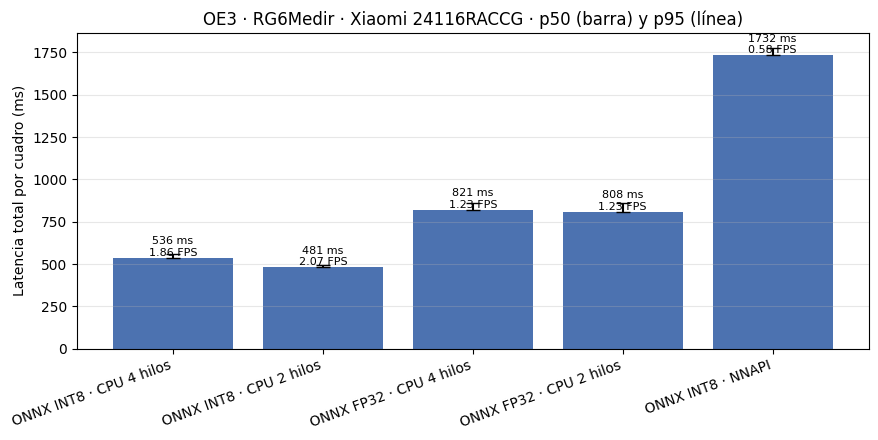

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(RESUMEN))
ax.bar(x, RESUMEN["total_p50_ms"], color="#4C72B0")
ax.errorbar(x, RESUMEN["total_p50_ms"], yerr=[np.zeros(len(RESUMEN)), RESUMEN["total_p95_ms"] - RESUMEN["total_p50_ms"]],
            fmt="none", ecolor="black", capsize=5)
for xi, (p50, fps) in enumerate(zip(RESUMEN["total_p50_ms"], RESUMEN["fps"])):
    ax.text(xi, p50, f"{p50:.0f} ms\n{fps:.2f} FPS", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(RESUMEN["modo"], rotation=20, ha="right")
ax.set_ylabel("Latencia total por cuadro (ms)")
ax.set_title(f"OE3 · RG6Medir · {EQUIPO.split('|')[0].strip()} · p50 (barra) y p95 (línea)")
ax.grid(axis="y", alpha=.3)
fig.tight_layout()
FIGURA = os.path.join(CARPETA, "latencia_android.png")
fig.savefig(FIGURA, dpi=200)
plt.show()

## 5) Guardar los resultados
Se guardan la tabla resumen y la figura.

In [5]:
RESUMEN.to_csv(os.path.join(CARPETA, "resumen_medicion.csv"), index=False)
os.makedirs(INFORME, exist_ok=True)
for archivo in ("resumen_medicion.csv", "latencia_android.png", "registro.csv"):
    shutil.copy2(os.path.join(CARPETA, archivo), INFORME)

def tabla_md(df):
    lineas = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lineas += ["| " + " | ".join(str(x) for x in fila) + " |" for fila in df.itertuples(index=False)]
    return "\n".join(lineas)

columnas = ["modo", "n", "total_p50_ms", "total_p95_ms", "total_media_ms", "total_ic95_lo_ms", "total_ic95_hi_ms", "fps",
            "pct_cuadros_menos_1s", "inferencia_p50_ms", "L_pct_vs_fp32", "temp_bat_min_c", "temp_bat_max_c"]
resumen = "\n".join([
    "# OE3 · Medición en el teléfono (RG6Medir)",
    "",
    f"- **Equipo:** {EQUIPO}.",
    "- **App:** RG6Medir (onnxruntime-android 1.27.0), botón «Medir». Modelos: los ONNX INT8 y FP32 de",
    "  `resultados/oe3/ptq_int8/` (ver `../ptq/classes.json`). Entrada rectangular 1024×768 (vertical).",
    "- **Protocolo:** 5 modos; por modo 5 cuadros de calentamiento y 100 medidos; 30 s de pausa entre modos; umbral",
    "  de confianza por clase F1-óptimo (`classes.json`).",
    f"- **Condiciones (declaradas por el tesista):** {CONDICIONES}.",
    f"- **Escena:** {ESCENA}.",
    "- **Latencia por cuadro (`total`):** preproceso (cuadro de cámara → letterbox → tensor) + inferencia + post-proceso",
    "  (decodificación, NMS y máscaras). Excluye el dibujo en pantalla. FPS = 1000 / media del total.",
    "  IC 95 % de la media por bootstrap (2000 remuestreos, semilla 42). L% = (FP32 − INT8) / FP32 con los mismos hilos.",
    "",
    tabla_md(RESUMEN[[c for c in columnas if c in RESUMEN.columns]]),
    "",
    "**A declarar:**",
    "1. Las detecciones del registro **no miden precisión** (dependen del encuadre); la precisión del OE3 es la del",
    "   test en `../resumen.md`.",
    "2. El orden de los modos es fijo, así que los últimos corren con el teléfono más caliente; ver las temperaturas",
    "   de batería y los estados térmicos en `resumen_medicion.csv`.",
    "",
    "Archivos: resumen_medicion.csv, latencia_android.png, registro.csv (registro crudo del teléfono).",
])
with open(os.path.join(INFORME, "resumen.md"), "w", encoding="utf-8") as f:
    f.write(resumen + "\n")
print("Medición del teléfono copiada a", INFORME)

Medición del teléfono copiada a /content/drive/MyDrive/tesis-rg6final/informe_para_codex/oe3/android
